In [1]:
### Libaries
import sklearn
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.table as tb
from sklearn.datasets import fetch_california_housing, fetch_openml
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import BaggingClassifier, ExtraTreesClassifier, RandomForestClassifier, AdaBoostClassifier, HistGradientBoostingClassifier, GradientBoostingRegressor, VotingClassifier, StackingClassifier
from sklearn.metrics import accuracy_score, root_mean_squared_error, mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, train_test_split

In [2]:
### Random Seed
RANDOM_SEEDS = [1,2,3,4,5]

In [3]:
### Data
fashionMNIST = fetch_openml('Fashion-MNIST')
californiaHousing = fetch_california_housing()

In [4]:
# split from last hw iris_utils
def stratified_split(X, y, test_fraction=0.3, seed=0):
    """Seeded, class-proportional train/test split."""
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for k in np.unique(y):
        idx_k = np.where(y == k)[0]
        rng.shuffle(idx_k)
        n_test_k = int(round(len(idx_k) * test_fraction))
        test_idx.extend(idx_k[:n_test_k])
        train_idx.extend(idx_k[n_test_k:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

In [5]:
# return the mean and standard deviation of a list of values
def mean_std(vals):
    n = len(vals)
    mu = sum(vals) / n

    s = 0
    for val in vals:
        s += (val-mu)**2
    std = (s / (n - 1))**0.5
    return (mu,std)

# given a list with [seeds][depth / other]
# return a list that has the (mean,std) tuples for the values
def calcStats(vals, depths):
    stats = []
    # not a defined list, just get the length of the columns
    if depths is None:
        depths = range(len(vals))
    # iterate by columns
    for i in range(len(depths)):
        valuesAcrossDepth = []
        # iterate through seeds and calculate mean,std
        for l in range(len(RANDOM_SEEDS)):
            valuesAcrossDepth.append(vals[l][i])
        stats.append(mean_std(valuesAcrossDepth))
    return stats
# Just formatting the mean, std
def combine(stats):
    return ["{:.3f} ± {:.3f} ".format(mu, std) for mu, std in stats]

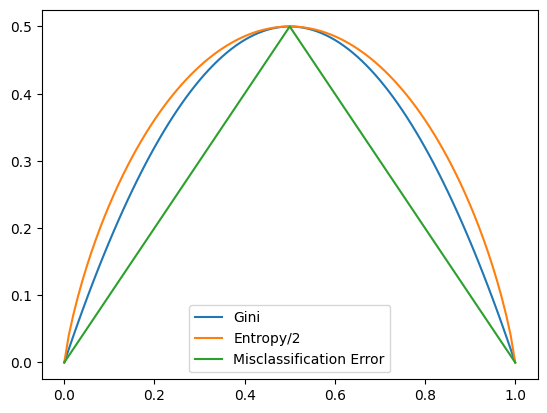

In [6]:
# part 1a - visualize the functions
# grab values 0 to 1 stepping 0.01
p = np.arange(0,1.01,0.01)
ginis = []
ents = []
misses = []
def gini(p):
    return 1 - p**2 - (1-p)**2
def ent(p):
    if p ==0 or p==1:
        return 0
    return -0.5*((p*np.log2(p)) + (1-p)*np.log2(1-p))
def mis(p):
    return 1 - max(p,1-p)

# calculate the functions
for val in p:
    ginis.append(gini(val))
    ents.append(ent(val))
    misses.append(mis(val))

# plot the results
plt.plot(p, ginis, label="Gini")
plt.plot(p, ents, label="Entropy/2")
plt.plot(p,misses, label="Misclassification Error")
plt.legend(loc='lower center')

In [7]:
### part 1b - how often the two criteria choose the same feature at the root and at depth 1–2
def getFeaturesAtDepth1_2(model):
    tree = model.tree_
    features = {}

    # root
    if tree.feature[0] != -2:
        features[""] = tree.feature[0]

    # depth 1
    left = tree.children_left[0]
    right = tree.children_right[0]

    # make sure it exists
    if left != -1 and tree.feature[left] != -2:
        features["L"] = tree.feature[left]
    if right != -1 and tree.feature[right] != -2:
        features["R"] = tree.feature[right]

    # depth 2
    for node, path in [(left, "L"), (right, "R")]: # iterate to L, R, RR, RL, LL, LR
        if node == -1:
            continue

        left2 = tree.children_left[node]
        right2 = tree.children_right[node]

        # make sure exists
        if left2 != -1 and tree.feature[left2] != -2:
            features[path + "L"] = tree.feature[left2]
        if right2 != -1 and tree.feature[right2] != -2:
            features[path + "R"] = tree.feature[right2]

    return features

In [39]:
# split data
xtrs = []
xvals = []
ytrs = []
yvals = []
xtes = []
ytes = []

for seed in RANDOM_SEEDS:
    # take 15k needed ~ 1/4 of dataset
    X = fashionMNIST.data[:15001].to_numpy()
    y = fashionMNIST.target[:15001].to_numpy()

    # split into 10,000 train, 5,000 val
    xtr, xval, ytr, yval = stratified_split(X, y, test_fraction=1/3, seed=seed)

    # take test
    xte = fashionMNIST.data[60000:].to_numpy()
    yte = fashionMNIST.target[60000:].to_numpy()

    xtrs.append(xtr)
    xvals.append(xval)
    ytrs.append(ytr)
    yvals.append(yval)
    xtes.append(xte)
    ytes.append(yte)

In [9]:
### Part 1b
entropyTrees = []
entropyTrainAccuracies = []
entropyValidationAccuracies = []
entropyTimes = []
entropyLeaves = []
entropyActualDepths = []
giniTrees = []
giniTrainAccuracies = []
giniValidationAccuracies = []
giniTimes = []
giniLeaves = []
giniActualDepths = []

for l in range(len(RANDOM_SEEDS)):
    print(seed)
    depths = [2,4,6,8,10,12,15,20,None]
    currEntropyTrees = []
    currEntropyTrainAccuracies = []
    currEntropyValidationAccuracies = []
    currEntropyTimes = []
    currEntropyLeaves = []
    currEntropyActualDepths = []

    for depth in depths:
        start = time.time()

        # create and fit tree
        entropyTree = DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_SEEDS[l], max_depth=depth)
        entropyTree.fit(xtrs[l], ytrs[l])

        # training accuracy
        entropyTreePredictions = entropyTree.predict(xtrs[l])
        entropyTrainAccuracy = accuracy_score(ytrs[l], entropyTreePredictions)

        # validation accuracy
        entropyTreePredictions = entropyTree.predict(xvals[l])
        entropyValidationAccuracy = accuracy_score(yvals[l], entropyTreePredictions)

        # update lists
        end = time.time()
        currEntropyTimes.append(end-start)
        currEntropyTrainAccuracies.append(entropyTrainAccuracy)
        currEntropyValidationAccuracies.append(entropyValidationAccuracy)
        currEntropyLeaves.append(entropyTree.get_n_leaves())
        currEntropyTrees.append(entropyTree)
        currEntropyActualDepths.append(entropyTree.get_depth())

    print("Entropy Done")
    currGiniTrees = []
    currGiniTrainAccuracies = []
    currGiniValidationAccuracies = []
    currGiniTimes = []
    currGiniLeaves = []
    currGiniActualDepths = []

    for depth in depths:
        start = time.time()

        # create and fit tree
        giniTree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[l], max_depth=depth)
        giniTree.fit(xtrs[l], ytrs[l])
        
        # training accuracy
        giniTreePredictions = giniTree.predict(xtrs[l])
        giniTrainError = accuracy_score(ytrs[l], giniTreePredictions)

        # validation accuracy
        giniTreePredictions = giniTree.predict(xvals[l])
        giniValidationError = accuracy_score(yvals[l], giniTreePredictions)

        # update lists
        end = time.time()
        currGiniTimes.append(end-start)
        currGiniTrainAccuracies.append(giniTrainError)
        currGiniValidationAccuracies.append(giniValidationError)
        currGiniLeaves.append(giniTree.get_n_leaves())
        currGiniActualDepths.append(giniTree.get_depth())
        currGiniTrees.append(giniTree)

    print("Gini Done")
    # append final values obtained
    entropyTrees.append(currEntropyTrees)
    entropyTrainAccuracies.append(currEntropyTrainAccuracies)
    entropyValidationAccuracies.append(currEntropyValidationAccuracies)
    entropyTimes.append(currEntropyTimes)
    entropyLeaves.append(currEntropyLeaves)
    entropyActualDepths.append(currEntropyActualDepths)
    giniTrees.append(currGiniTrees)
    giniTrainAccuracies.append(currGiniTrainAccuracies)
    giniValidationAccuracies.append(currGiniValidationAccuracies)
    giniTimes.append(currGiniTimes)
    giniLeaves.append(currGiniLeaves)
    giniActualDepths.append(currGiniActualDepths)


5
Entropy Done
Gini Done
5
Entropy Done
Gini Done
5
Entropy Done
Gini Done
5
Entropy Done
Gini Done
5
Entropy Done
Gini Done


In [10]:
#just get the mean,std estimates
entropyTrainAccStats = calcStats(entropyTrainAccuracies, depths=depths)
entropyValidationAccStats = calcStats(entropyValidationAccuracies, depths=depths)
entropyTimeStats = calcStats(entropyTimes, depths=depths)
entropyLeaveStats= calcStats(entropyLeaves, depths=depths)
entropyAcDepthStats = calcStats(entropyActualDepths, depths=depths)
giniTrainAccStats = calcStats(giniTrainAccuracies, depths=depths)
giniValidationAccStats = calcStats(giniValidationAccuracies, depths=depths)
giniTimeStats = calcStats(giniTimes, depths=depths)
giniLeaveStats = calcStats(giniLeaves, depths=depths)
giniAcDepthStats = calcStats(giniActualDepths, depths=depths)

In [11]:
# Part 1c - matches at depth
# compare features located on both trees, at root, depth1, depth 2
rootList = []
depth1List = []
depth2list = []

for l in range(len(RANDOM_SEEDS)):
    matches = [0, 0, 0]
    totals = [0, 0, 0]

    for entropyTree, giniTree in zip(entropyTrees[l], giniTrees[l]):
        entropyFeatures = getFeaturesAtDepth1_2(entropyTree)
        giniFeatures = getFeaturesAtDepth1_2(giniTree)

        # total positions for both trees via union
        paths = entropyFeatures.keys() | giniFeatures.keys()

        for path in paths:
            depth = len(path)
            totals[depth] += 1

            # make sure path exists for both
            if path in entropyFeatures and path in giniFeatures:
                # if match increment matches at depth counter
                if entropyFeatures[path] == giniFeatures[path]:
                    matches[depth] += 1
                    
    # division by zero check
    if totals[0] > 0:
        rootList.append(matches[0] / totals[0])
    if totals[1] > 0:
        depth1List.append(matches[1] / totals[1])
    if totals[2] > 0:
        depth2list.append(matches[2] / totals[2])

#calculate estimates
rootMean, rootStd = mean_std(rootList)
depth1Mean, depth1Std = mean_std(depth1List)
depth2Mean, depth2Std = mean_std(depth2list)
totalmean, totalstd = mean_std(rootList + depth1List + depth2list)

print("Root agreement: {:.3f} ± {:.3f}".format(rootMean, rootStd))
print("Depth 1 agreement: {:.3f} ± {:.3f}".format(depth1Mean, depth1Std))
print("Depth 2 agreement: {:.3f} ± {:.3f}".format(depth2Mean, depth2Std))
print("Total agreement: {:.3f} ± {:.3f}".format(depth2Mean, depth2Std))

Root agreement: 0.000 ± 0.000
Depth 1 agreement: 0.000 ± 0.000
Depth 2 agreement: 0.050 ± 0.112
Total agreement: 0.050 ± 0.112


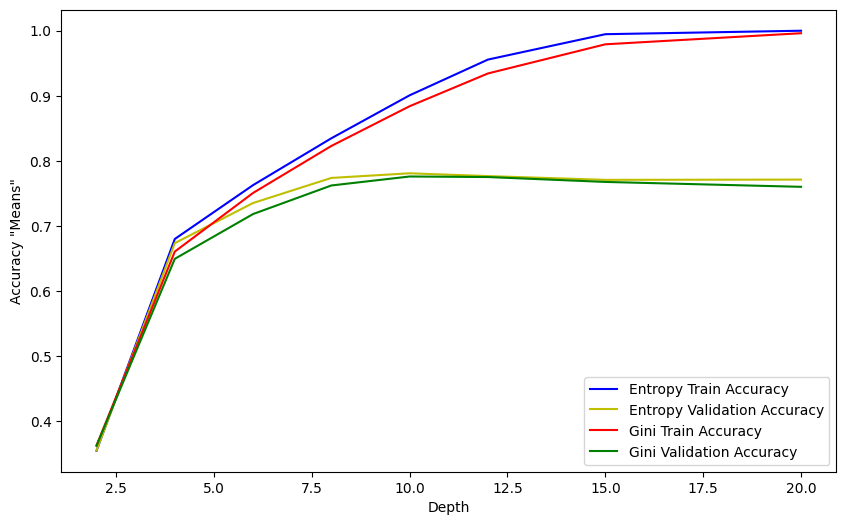

In [12]:
### part 1b - train and validation accuracy vs. depth (one plot, both criteria)
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(depths, [i[0] for i in entropyTrainAccStats], label='Entropy Train Accuracy', color='b')
ax.plot(depths, [i[0] for i in entropyValidationAccStats], label='Entropy Validation Accuracy', color='y')
ax.set_xlabel('Depth')
ax.set_ylabel('Accuracy "Means"')
ax.plot(depths, [i[0] for i in giniTrainAccStats], label='Gini Train Accuracy', color='r')
ax.plot(depths, [i[0] for i in giniValidationAccStats], label='Gini Validation Accuracy', color='g')
ax.legend(loc='lower right')

C:\Users\jafer\AppData\Local\Temp\ipykernel_3420\546662272.py:21: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


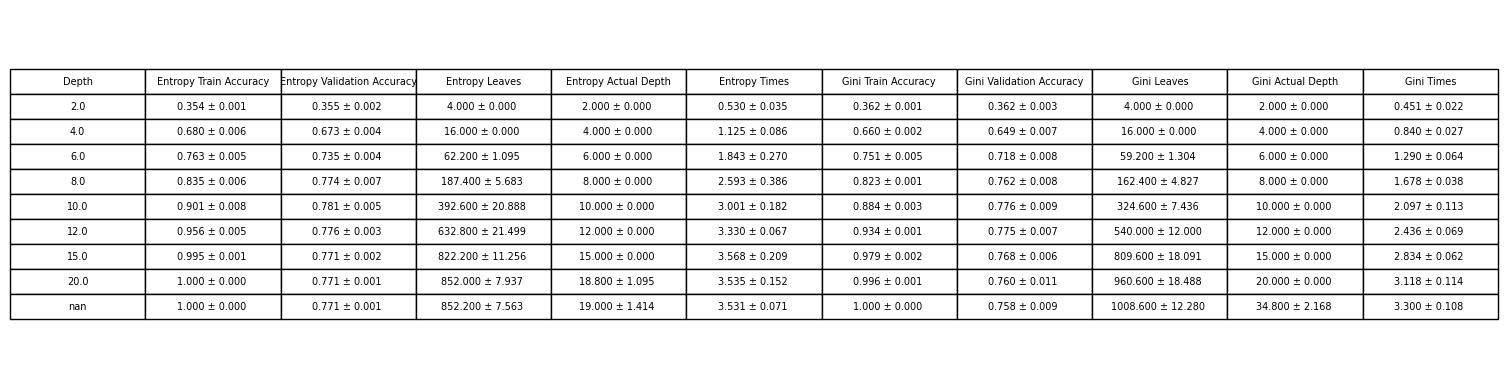

In [13]:
### part 1b - training time, number of leaves and actual depth & mean ± std over 5 random seeds or subsamples
table = pd.DataFrame({
    'Depth': depths,
    'Entropy Train Accuracy': combine(entropyTrainAccStats),
    'Entropy Validation Accuracy': combine(entropyValidationAccStats),
    'Entropy Leaves': combine(entropyLeaveStats),
    'Entropy Actual Depth': combine(entropyAcDepthStats),
    'Entropy Times': combine(entropyTimeStats),
    'Gini Train Accuracy': combine(giniTrainAccStats),
    'Gini Validation Accuracy': combine(giniValidationAccStats),
    'Gini Leaves': combine(giniLeaveStats),
    'Gini Actual Depth': combine(giniAcDepthStats),
    'Gini Times': combine(giniTimeStats)
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3, 1.5)
plt.tight_layout()
plt.show()


In [14]:
### part 1c pruning
import random

validationAccuracies = []
leafCounts = []
selectedAlphas = []
useAlphas = []

# compute the cost complexity path
for l in range(len(RANDOM_SEEDS)):
    tree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[l])
    path = tree.cost_complexity_pruning_path(xtr, ytr)
    selectedAlphas.extend(path.ccp_alphas)

# select say 20 values
# https://numpy.org/doc/stable/user/how-to-partition.html
indices = np.linspace(0, len(selectedAlphas) - 1, 20, dtype=int)
for i in indices:
    useAlphas.append(selectedAlphas[i])

# these will be the actual alpha values we use
useAlphas.sort()

# iterate through and calculate train and validationa accuracies
for l in range(len(RANDOM_SEEDS)):
    print(l)
    xtr = xtrs[l]
    ytr = ytrs[l]
    xval = xvals[l]
    yval = yvals[l]

    tree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[l])

    currValidationAccuracies = []
    currLeafCounts = []

    # try each alpha
    for i,alpha in enumerate(useAlphas):
        ccpTree = DecisionTreeClassifier(criterion='gini', ccp_alpha = alpha, random_state=RANDOM_SEEDS[0])
        ccpTree.fit(xtr,ytr)
        predict = ccpTree.predict(xval)
        currValidationAccuracies.append(accuracy_score(predict, yval))
        currLeafCounts.append(ccpTree.get_n_leaves())
    validationAccuracies.append(currValidationAccuracies)
    leafCounts.append(currLeafCounts)

0
1
2
3
4


In [15]:
# get mean and std estimate, mean_std isn't necessary here
validationAccuracyMeans = np.mean(validationAccuracies, axis=0)
validationAccuracyStds = np.std(validationAccuracies, axis=0)
leafCountMeans = np.mean(leafCounts, axis=0)
leafCountStds = np.std(leafCounts, axis=0)

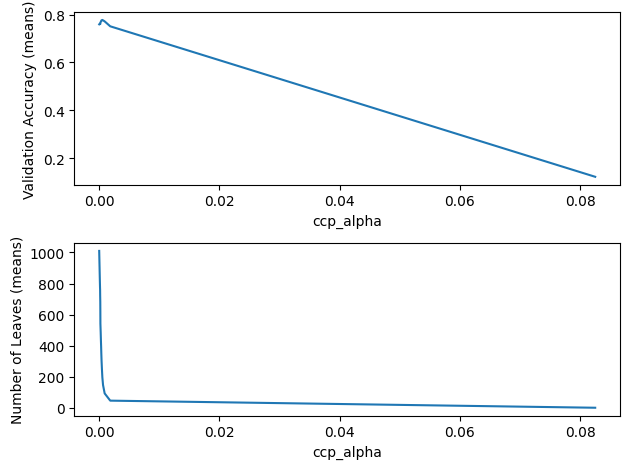

In [16]:
# P1c plot validation accuracy and leaft count vs alpha
fig, ax = plt.subplots(2, 1)

ax[0].plot(useAlphas,validationAccuracyMeans)
ax[0].set_xlabel('ccp_alpha')
ax[0].set_ylabel('Validation Accuracy (means)')

ax[1].plot(useAlphas, leafCountMeans)
ax[1].set_xlabel('ccp_alpha')
ax[1].set_ylabel('Number of Leaves (means)')

plt.tight_layout()
plt.show()

In [17]:
#https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
grid = GridSearchCV(
    DecisionTreeClassifier(
        criterion='gini',
        random_state=RANDOM_SEEDS[0]
    ),
    param_grid={'ccp_alpha': useAlphas},
    cv=5,
    scoring='accuracy',
)

grid.fit(xtr,ytr)
best = grid.best_params_["ccp_alpha"]

print("Optimal Alpha: {:.4f}".format(best))
print("Best Pruning Test Accuracy {:.4f}".format(grid.best_estimator_.score(xval,yval)))

Optimal Alpha: 0.0006
Best Pruning Test Accuracy 0.7708


In [18]:
### best depth was None
tree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[0], max_depth=20)
tree.fit(xtr,ytr)
print("Best Depth-Limited Tree Test Accuracy : {:.4f}".format(tree.score(xte, yte)))

Best Depth-Limited Tree Test Accuracy : 0.7468


In [19]:
# part 1c, trying min_samples_leaf
### part 1c pruning
import random

mslTrees = []
mslValidationAccuracies = []
mslLeafCounts = []
minSamplesLeaf = [1,5,20,50]

# iterate through and calculate validation accuracies and leaf counts
for l in range(len(RANDOM_SEEDS)):
    print(l)
    currValidationAccuracies = []
    currLeafCounts = []
    currMslTrees = []
    for msl in minSamplesLeaf:
        mslTree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[l], min_samples_leaf=msl)
        mslTree.fit(xtrs[l], ytrs[l])

        validationPredictions = mslTree.predict(xvals[l])
        currValidationAccuracies.append(accuracy_score(yvals[l], validationPredictions))

        currLeafCounts.append(mslTree.get_n_leaves())
        currMslTrees.append(mslTree)
    mslValidationAccuracies.append(currValidationAccuracies)
    mslLeafCounts.append(currLeafCounts)
    mslTrees.append(currMslTrees)

0
1
2
3
4


In [20]:
# part 1c - min samples leaf statistics
mslValidationAccuracyStats = calcStats(mslValidationAccuracies, depths=minSamplesLeaf)
mslLeafStats = calcStats(mslLeafCounts, depths=minSamplesLeaf)

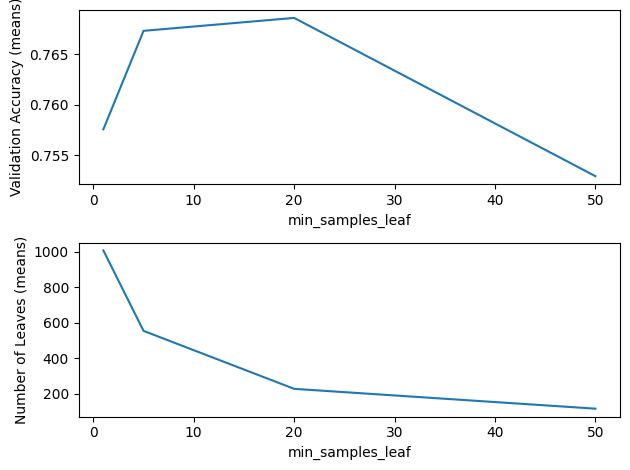

In [21]:
# P1c plot validation accuracy and leaft count vs min_samples_Leaf
fig, ax = plt.subplots(2, 1)

ax[0].plot(minSamplesLeaf,[i[0] for i in mslValidationAccuracyStats])
ax[0].set_xlabel('min_samples_leaf')
ax[0].set_ylabel('Validation Accuracy (means)')

ax[1].plot(minSamplesLeaf, [i[0] for i in mslLeafStats])
ax[1].set_xlabel('min_samples_leaf')
ax[1].set_ylabel('Number of Leaves (means)')

plt.tight_layout()
plt.show()

In [22]:
# we can see the best one clearly, but use this anyway to grab score easier
grid = GridSearchCV(
    DecisionTreeClassifier(
        criterion='gini',
        random_state=RANDOM_SEEDS[0]
    ),
    param_grid={'min_samples_leaf': minSamplesLeaf},
    cv=5,
    scoring='accuracy',
)

grid.fit(xtr,ytr)
best = grid.best_params_["min_samples_leaf"]

print("Optimal min_samples_leaf: {:.4f}".format(best))
print("Best min_samples_leaf Test Accuracy {:.4f}".format(grid.best_estimator_.score(xval,yval)))

Optimal min_samples_leaf: 5.0000
Best min_samples_leaf Test Accuracy 0.7648


In [33]:
# part 1d regression - get data
regX = californiaHousing.data
regy = californiaHousing.target

regxtrs,regxvals,regytrs,regyvals,regxtes,regytes = [],[],[],[],[],[]

for l in RANDOM_SEEDS:
    regxtr, regxte, regytr, regyte = train_test_split(regX,regy, test_size=0.2, random_state=l)
    regxtr,regxval, regytr,regyval = train_test_split(regxtr,regytr, test_size=0.2, random_state=l)
    regxtrs.append(regxtr)
    regytrs.append(regytr)
    regxvals.append(regxval)
    regyvals.append(regyval)
    regxtes.append(regxte)
    regytes.append(regyte)


In [34]:
### Part 1d regression
# done in a similar way to 1b
# i know the variables should be called error/errors not accuracy, but it would take a while to rename all
rmseTrees = []

rmseTrainMSEAccuracies = []
rmseTrainRMSEAccuracies = []
rmseTrainMAEAccuracies = []

rmseValidationMSEAccuracies = []
rmseValidationRMSEAccuracies = []
rmseValidationMAEAccuracies = []

maeTrees = []

maeTrainMSEAccuracies = []
maeTrainRMSEAccuracies = []
maeTrainMAEAccuracies = []

maeValidationMSEAccuracies = []
maeValidationRMSEAccuracies = []
maeValidationMAEAccuracies = []

friedTrees = []

friedTrainMSEAccuracies = []
friedTrainRMSEAccuracies = []
friedTrainMAEAccuracies = []

friedValidationMSEAccuracies = []
friedValidationRMSEAccuracies = []
friedValidationMAEAccuracies = []

depths = [2,4,6,8,10]

for l in range(len(RANDOM_SEEDS)):
    print(l)
    currRmseTrees = []

    currRmseTrainMSEAccuracies = []
    currRmseTrainRMSEAccuracies = []
    currRmseTrainMAEAccuracies = []

    currRmseValidationMSEAccuracies = []
    currRmseValidationRMSEAccuracies = []
    currRmseValidationMAEAccuracies = []

    currMaeTrees = []

    currMaeTrainMSEAccuracies = []
    currMaeTrainRMSEAccuracies = []
    currMaeTrainMAEAccuracies = []

    currMaeValidationMSEAccuracies = []
    currMaeValidationRMSEAccuracies = []
    currMaeValidationMAEAccuracies = []

    currFriedTrees = []

    currFriedTrainMSEAccuracies = []
    currFriedTrainRMSEAccuracies = []
    currFriedTrainMAEAccuracies = []

    currFriedValidationMSEAccuracies = []
    currFriedValidationRMSEAccuracies = []
    currFriedValidationMAEAccuracies = []

    for depth in depths:
        print(depth)
        # create and fit tree
        rmseTree = DecisionTreeRegressor(criterion='squared_error', random_state=RANDOM_SEEDS[l], max_depth=depth)
        rmseTree.fit(regxtrs[l], regytrs[l])

        # training accuracy
        rmseTreePredictions = rmseTree.predict(regxtrs[l])
        rmseTreeTrainMSEAccuracy = mean_squared_error(regytrs[l], rmseTreePredictions)
        rmseTreeTrainRMSEAccuracy = root_mean_squared_error(regytrs[l], rmseTreePredictions)
        rmseTreeTrainMAEAccuracy = mean_absolute_error(regytrs[l], rmseTreePredictions)

        # validation accuracy
        rmseTreePredictions = rmseTree.predict(xvals[l])
        rmseTreeValidationMSEAccuracy = mean_squared_error(regyvals[l], rmseTreePredictions)
        rmseTreeValidationRMSEAccuracy = root_mean_squared_error(regyvals[l], rmseTreePredictions)
        rmseTreeValidationMAEAccuracy = mean_absolute_error(regyvals[l], rmseTreePredictions)

        # update lists
        currRmseTrees.append(rmseTree)

        currRmseTrainMSEAccuracies.append(rmseTreeTrainMSEAccuracy)
        currRmseTrainRMSEAccuracies.append(rmseTreeTrainRMSEAccuracy)
        currRmseTrainMAEAccuracies.append(rmseTreeTrainMAEAccuracy)

        currRmseValidationMSEAccuracies.append(rmseTreeValidationMSEAccuracy)
        currRmseValidationRMSEAccuracies.append(rmseTreeValidationRMSEAccuracy)
        currRmseValidationMAEAccuracies.append(rmseTreeValidationMAEAccuracy)

    print("RMSE Done")

    for depth in depths:
        print(depth)
        # create and fit tree
        maeTree = DecisionTreeRegressor(criterion='absolute_error', random_state=RANDOM_SEEDS[l], max_depth=depth)
        maeTree.fit(regxtrs[l], regytrs[l])

        # training accuracy
        maeTreePredictions = maeTree.predict(regxtrs[l])
        maeTreeTrainMSEAccuracy = mean_squared_error(regytrs[l], maeTreePredictions)
        maeTreeTrainRMSEAccuracy = root_mean_squared_error(regytrs[l], maeTreePredictions)
        maeTreeTrainMAEAccuracy = mean_absolute_error(regytrs[l], maeTreePredictions)

        # validation accuracy
        maeTreePredictions = maeTree.predict(regxvals[l])
        maeTreeValidationMSEAccuracy = mean_squared_error(regyvals[l], maeTreePredictions)
        maeTreeValidationRMSEAccuracy = root_mean_squared_error(regyvals[l], maeTreePredictions)
        maeTreeValidationMAEAccuracy = mean_absolute_error(regyvals[l], maeTreePredictions)

        # update lists
        currMaeTrees.append(maeTree)

        currMaeTrainMSEAccuracies.append(maeTreeTrainMSEAccuracy)
        currMaeTrainRMSEAccuracies.append(maeTreeTrainRMSEAccuracy)
        currMaeTrainMAEAccuracies.append(maeTreeTrainMAEAccuracy)

        currMaeValidationMSEAccuracies.append(maeTreeValidationMSEAccuracy)
        currMaeValidationRMSEAccuracies.append(maeTreeValidationRMSEAccuracy)
        currMaeValidationMAEAccuracies.append(maeTreeValidationMAEAccuracy)

    print("MAE Done")

    for depth in depths:
        print(depth)
        # create and fit tree
        friedTree = DecisionTreeRegressor(criterion='friedman_mse', random_state=RANDOM_SEEDS[l], max_depth=depth)
        friedTree.fit(xtrs[l], ytrs[l])

        # training accuracy
        friedTreePredictions = friedTree.predict(xtrs[l])
        friedTreeTrainMSEAccuracy = mean_squared_error(regytrs[l], friedTreePredictions)
        friedTreeTrainRMSEAccuracy = root_mean_squared_error(regytrs[l], friedTreePredictions)
        friedTreeTrainMAEAccuracy = mean_absolute_error(regytrs[l], friedTreePredictions)

        # validation accuracy
        friedTreePredictions = friedTree.predict(regxvals[l])
        friedTreeValidationMSEAccuracy = mean_squared_error(regyvals[l], friedTreePredictions)
        friedTreeValidationRMSEAccuracy = root_mean_squared_error(regyvals[l], friedTreePredictions)
        friedTreeValidationMAEAccuracy = mean_absolute_error(regyvals[l], friedTreePredictions)

        # update lists
        currFriedTrees.append(friedTree)

        currFriedTrainMSEAccuracies.append(friedTreeTrainMSEAccuracy)
        currFriedTrainRMSEAccuracies.append(friedTreeTrainRMSEAccuracy)
        currFriedTrainMAEAccuracies.append(friedTreeTrainMAEAccuracy)

        currFriedValidationMSEAccuracies.append(friedTreeValidationMSEAccuracy)
        currFriedValidationRMSEAccuracies.append(friedTreeValidationRMSEAccuracy)
        currFriedValidationMAEAccuracies.append(friedTreeValidationMAEAccuracy)

    print("Fried Done")

    rmseTrees.append(currRmseTrees)

    rmseTrainMSEAccuracies.append(currRmseTrainMSEAccuracies)
    rmseTrainRMSEAccuracies.append(currRmseTrainRMSEAccuracies)
    rmseTrainMAEAccuracies.append(currRmseTrainMAEAccuracies)

    rmseValidationMSEAccuracies.append(currRmseValidationMSEAccuracies)
    rmseValidationRMSEAccuracies.append(currRmseValidationRMSEAccuracies)
    rmseValidationMAEAccuracies.append(currRmseValidationMAEAccuracies)

    maeTrees.append(currMaeTrees)

    maeTrainMSEAccuracies.append(currMaeTrainMSEAccuracies)
    maeTrainRMSEAccuracies.append(currMaeTrainRMSEAccuracies)
    maeTrainMAEAccuracies.append(currMaeTrainMAEAccuracies)

    maeValidationMSEAccuracies.append(currMaeValidationMSEAccuracies)
    maeValidationRMSEAccuracies.append(currMaeValidationRMSEAccuracies)
    maeValidationMAEAccuracies.append(currMaeValidationMAEAccuracies)

    friedTrees.append(currFriedTrees)

    friedTrainMSEAccuracies.append(currFriedTrainMSEAccuracies)
    friedTrainRMSEAccuracies.append(currFriedTrainRMSEAccuracies)
    friedTrainMAEAccuracies.append(currFriedTrainMAEAccuracies)

    friedValidationMSEAccuracies.append(currFriedValidationMSEAccuracies)
    friedValidationRMSEAccuracies.append(currFriedValidationRMSEAccuracies)
    friedValidationMAEAccuracies.append(currFriedValidationMAEAccuracies)

0
2
4
6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8
10
Fried Done
1
2
4
6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8
10
Fried Done
2
2
4
6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8
10
Fried Done
3
2
4
6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8
10
Fried Done
4
2
4
6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8
10
Fried Done


In [12]:
# calc stats similarly again
rmseTrainMSEAccuracyStats = calcStats(rmseTrainMSEAccuracies, depths=depths)
rmseTrainRMSEAccuracyStats = calcStats(rmseTrainRMSEAccuracies, depths=depths)
rmseTrainMAEAccuracyStats = calcStats(rmseTrainMAEAccuracies, depths=depths)

rmseValidationMSEAccuracyStats = calcStats(rmseValidationMSEAccuracies, depths=depths)
rmseValidationRMSEAccuracyStats = calcStats(rmseValidationRMSEAccuracies, depths=depths)
rmseValidationMAEAccuracyStats = calcStats(rmseValidationMAEAccuracies, depths=depths)

maeTrainMSEAccuracyStats = calcStats(maeTrainMSEAccuracies, depths=depths)
maeTrainRMSEAccuracyStats = calcStats(maeTrainRMSEAccuracies, depths=depths)
maeTrainMAEAccuracyStats = calcStats(maeTrainMAEAccuracies, depths=depths)

maeValidationMSEAccuracyStats = calcStats(maeValidationMSEAccuracies, depths=depths)
maeValidationRMSEAccuracyStats = calcStats(maeValidationRMSEAccuracies, depths=depths)
maeValidationMAEAccuracyStats = calcStats(maeValidationMAEAccuracies, depths=depths)

friedTrainMSEAccuracyStats = calcStats(friedTrainMSEAccuracies, depths=depths)
friedTrainRMSEAccuracyStats = calcStats(friedTrainRMSEAccuracies, depths=depths)
friedTrainMAEAccuracyStats = calcStats(friedTrainMAEAccuracies, depths=depths)

friedValidationMSEAccuracyStats = calcStats(friedValidationMSEAccuracies, depths=depths)
friedValidationRMSEAccuracyStats = calcStats(friedValidationRMSEAccuracies, depths=depths)
friedValidationMAEAccuracyStats = calcStats(friedValidationMAEAccuracies, depths=depths)

C:\Users\jafer\AppData\Local\Temp\ipykernel_21936\1847463415.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


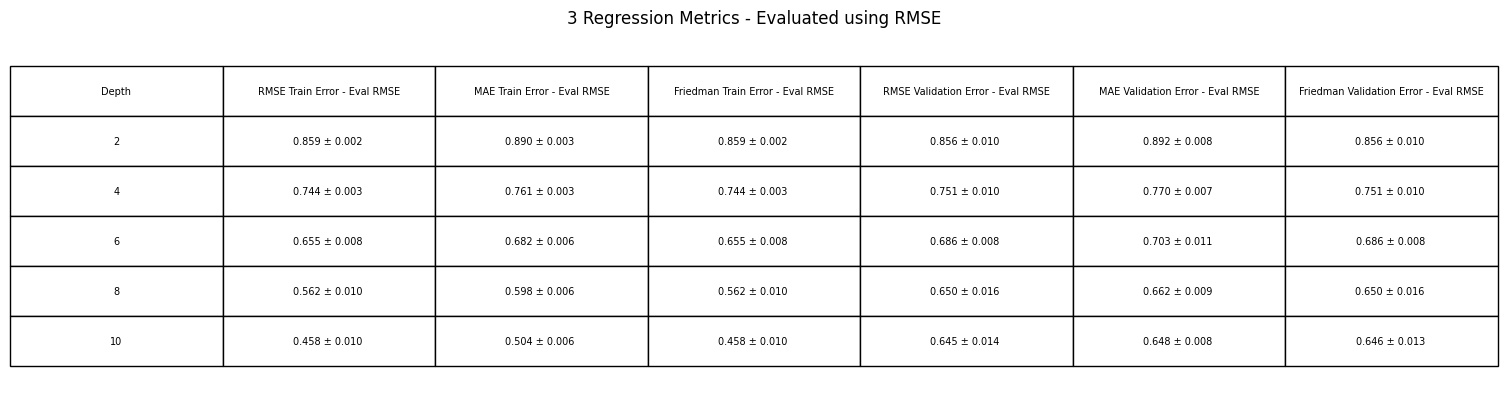

In [13]:
# part 1d plot rmse eval
table = pd.DataFrame({
    'Depth': depths,
    'RMSE Train Error - Eval RMSE' : combine(rmseTrainRMSEAccuracyStats),
    'MAE Train Error - Eval RMSE': combine(maeTrainRMSEAccuracyStats),
    'Friedman Train Error - Eval RMSE' : combine(friedTrainRMSEAccuracyStats),
    'RMSE Validation Error - Eval RMSE' : combine(rmseValidationRMSEAccuracyStats),
    'MAE Validation Error - Eval RMSE': combine(maeValidationRMSEAccuracyStats),
    'Friedman Validation Error - Eval RMSE' : combine(friedValidationRMSEAccuracyStats),
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3,3)
axtable.set
plt.title("3 Regression Metrics - Evaluated using RMSE")
plt.tight_layout()
plt.show()

C:\Users\jafer\AppData\Local\Temp\ipykernel_21936\3409220309.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


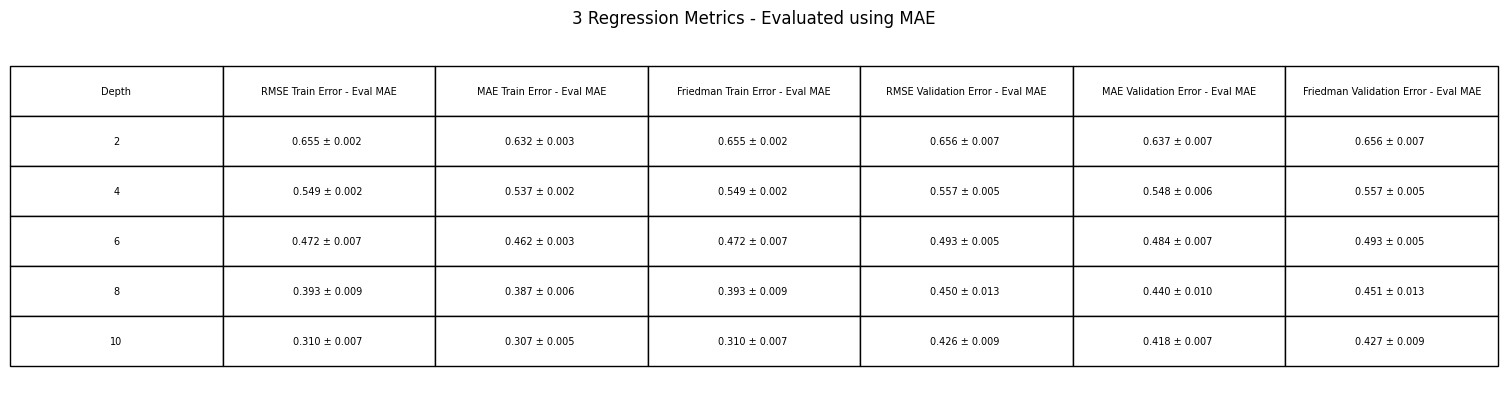

In [14]:
# part 1d plot mae eval
table = pd.DataFrame({
    'Depth': depths,
    'RMSE Train Error - Eval MAE' : combine(rmseTrainMAEAccuracyStats),
    'MAE Train Error - Eval MAE': combine(maeTrainMAEAccuracyStats),
    'Friedman Train Error - Eval MAE' : combine(friedTrainMAEAccuracyStats),
    'RMSE Validation Error - Eval MAE' : combine(rmseValidationMAEAccuracyStats),
    'MAE Validation Error - Eval MAE': combine(maeValidationMAEAccuracyStats),
    'Friedman Validation Error - Eval MAE' : combine(friedValidationMAEAccuracyStats),
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3,3)
axtable.set
plt.title("3 Regression Metrics - Evaluated using MAE")
plt.tight_layout()
plt.show()

C:\Users\jafer\AppData\Local\Temp\ipykernel_21936\3769093511.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


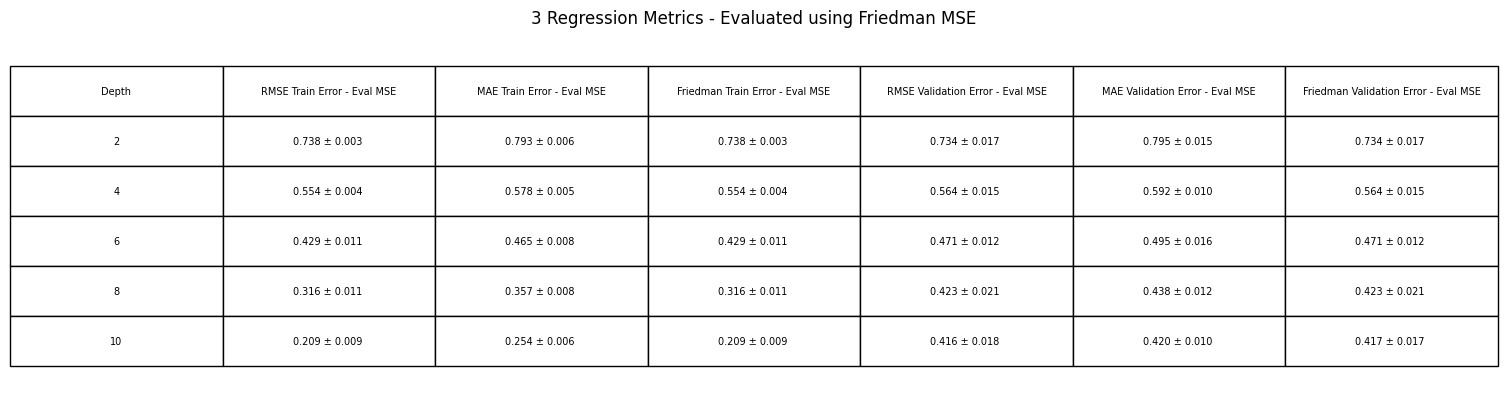

In [15]:
# part 1d plot fried eval
table = pd.DataFrame({
    'Depth': depths,
    'RMSE Train Error - Eval MSE' : combine(rmseTrainMSEAccuracyStats),
    'MAE Train Error - Eval MSE': combine(maeTrainMSEAccuracyStats),
    'Friedman Train Error - Eval MSE' : combine(friedTrainMSEAccuracyStats),
    'RMSE Validation Error - Eval MSE' : combine(rmseValidationMSEAccuracyStats),
    'MAE Validation Error - Eval MSE': combine(maeValidationMSEAccuracyStats),
    'Friedman Validation Error - Eval MSE' : combine(friedValidationMSEAccuracyStats),
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3,3)
axtable.set
plt.title("3 Regression Metrics - Evaluated using Friedman MSE")
plt.tight_layout()
plt.show()

Text(0.5, 1.0, '3 Regression metrics - Evaluated using RMSE')

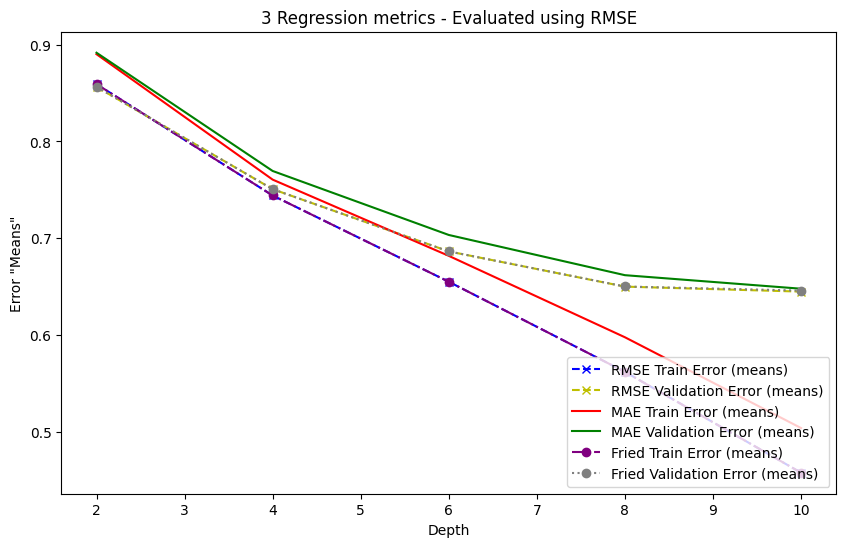

In [16]:
# visualize it all on RMSE
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(depths, [i[0] for i in rmseTrainRMSEAccuracyStats], label='RMSE Train Error (means)', color='b', linestyle='--', marker='x')
ax.plot(depths, [i[0] for i in rmseValidationRMSEAccuracyStats], label='RMSE Validation Error (means)', color='y', linestyle='--', marker='x')
ax.plot(depths, [i[0] for i in maeTrainRMSEAccuracyStats], label='MAE Train Error (means)', color='r')
ax.plot(depths, [i[0] for i in maeValidationRMSEAccuracyStats], label='MAE Validation Error (means)', color='g')
ax.plot(depths, [i[0] for i in friedTrainRMSEAccuracyStats], label='Fried Train Error (means)', color='purple',linestyle='-.', marker='o')
ax.plot(depths, [i[0] for i in friedValidationRMSEAccuracyStats], label='Fried Validation Error (means)', color='grey',linestyle=':', marker='o')
ax.set_xlabel('Depth')
ax.set_ylabel('Error "Means"')
ax.legend(loc='lower right')
ax.set_title("3 Regression metrics - Evaluated using RMSE")

Text(0.5, 1.0, '3 Regression metrics - Evaluated using MAE')

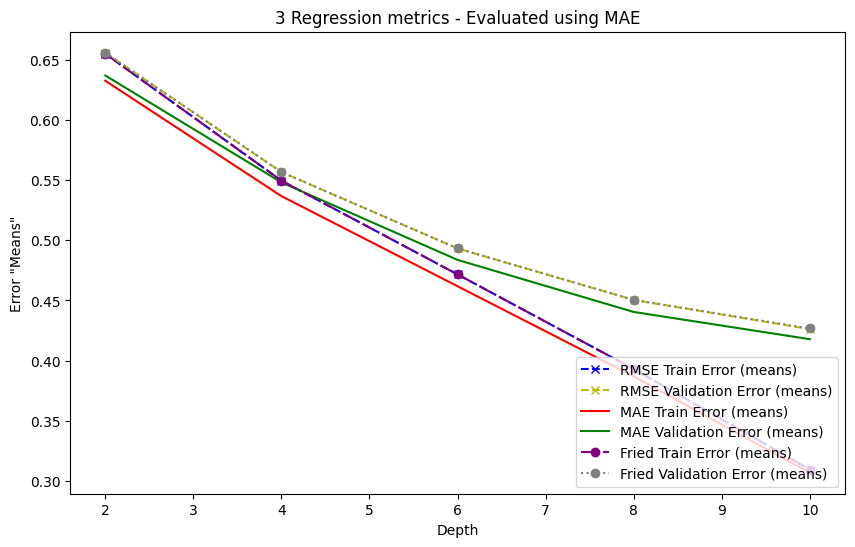

In [17]:
# visualize it all on MAE
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(depths, [i[0] for i in rmseTrainMAEAccuracyStats], label='RMSE Train Error (means)', color='b', linestyle='--', marker='x')
ax.plot(depths, [i[0] for i in rmseValidationMAEAccuracyStats], label='RMSE Validation Error (means)', color='y', linestyle='--', marker='x')
ax.plot(depths, [i[0] for i in maeTrainMAEAccuracyStats], label='MAE Train Error (means)', color='r')
ax.plot(depths, [i[0] for i in maeValidationMAEAccuracyStats], label='MAE Validation Error (means)', color='g')
ax.plot(depths, [i[0] for i in friedTrainMAEAccuracyStats], label='Fried Train Error (means)', color='purple',linestyle='-.', marker='o')
ax.plot(depths, [i[0] for i in friedValidationMAEAccuracyStats], label='Fried Validation Error (means)', color='grey',linestyle=':', marker='o')
ax.set_xlabel('Depth')
ax.set_ylabel('Error "Means"')
ax.legend(loc='lower right')
ax.set_title("3 Regression metrics - Evaluated using MAE")

In [35]:
# part 1d get best tree
bestTree = None
bestRMSE = float('inf')
seed = None

for tree in maeTrees:
    for l in range(len(RANDOM_SEEDS)):
        preds = tree[l].predict(regxtes[l])
        score = root_mean_squared_error(regytes[l], preds)

        if score <bestRMSE:
            bestRMSE = score
            bestTree = tree[l]
            seed = l

for tree in rmseTrees:
    for l in range(len(RANDOM_SEEDS)):
        preds = tree[l].predict(regxtes[l])
        score = root_mean_squared_error(regytes[l], preds)

        if score <bestRMSE:
            bestRMSE = score
            bestTree = tree[l]
            seed = l

for tree in friedTrees:
    for l in range(len(RANDOM_SEEDS)):
        preds = tree[l].predict(regxtes[l])
        score = root_mean_squared_error(regytes[l], preds)

        if score <bestRMSE:
            bestRMSE = score
            bestTree = tree[l]
            seed = l

print("Best Test RMSE: {:.3f}".format(bestRMSE))

Best Test RMSE: 0.514


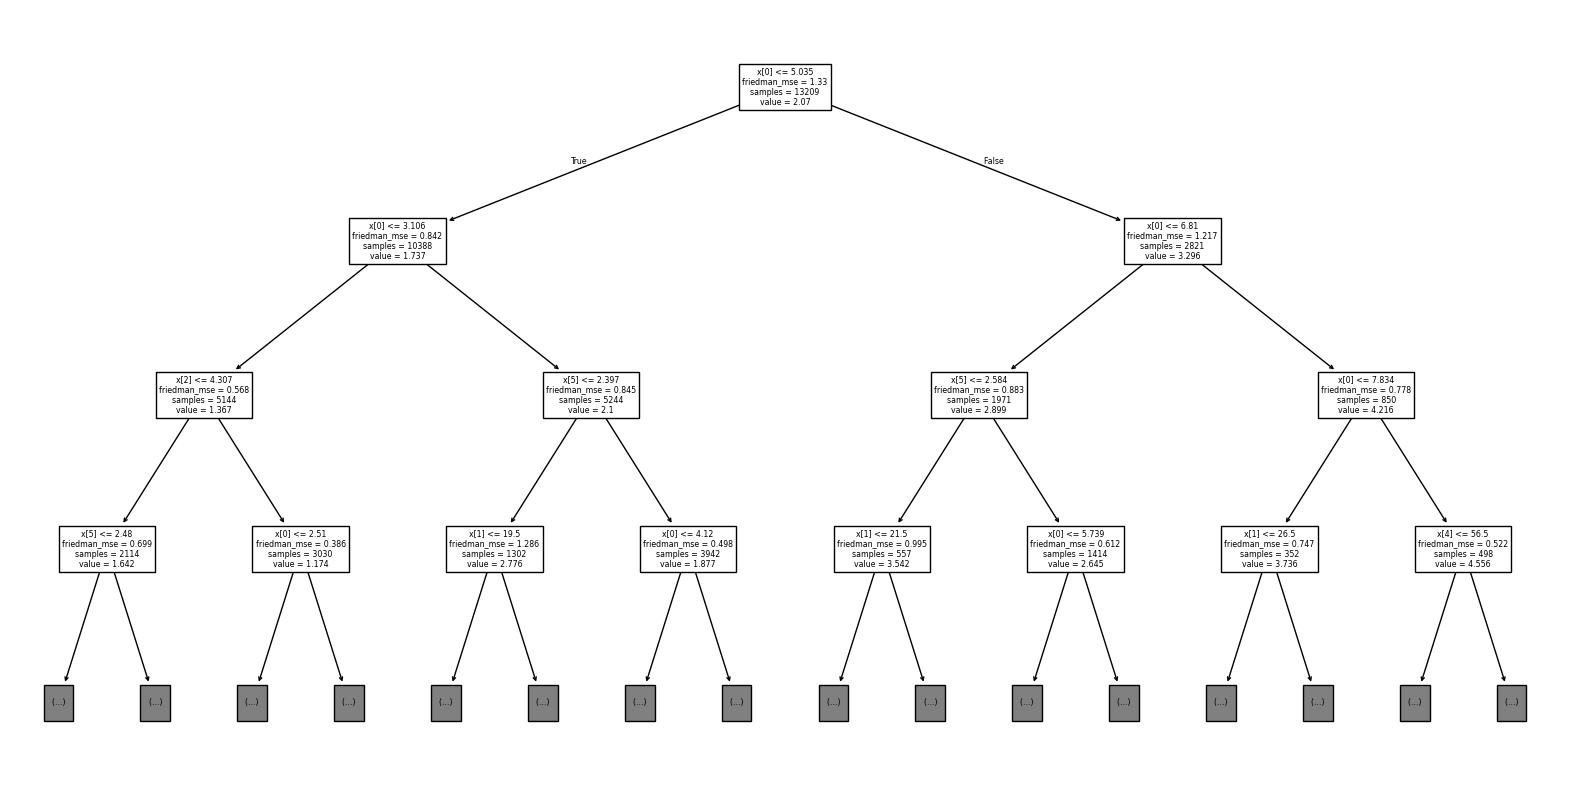

['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [20]:
# part 1d look at the top three levels of the best tree
plt.figure(figsize=(20,10))

plot_tree(
    bestTree, 
    max_depth=3,
)
plt.show()

print(fetch_california_housing().feature_names)

Text(0, 0.5, 'Predicted Price')

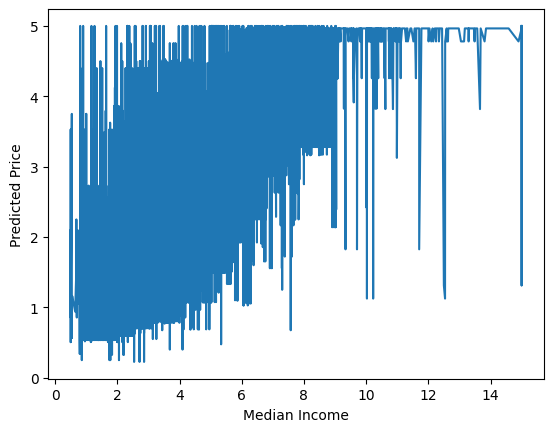

In [36]:
# part 1d visualize step function prediction
MedInc = regX[:,0]

# best tree preds
preds = bestTree.predict(X)

# sort feature
indx = np.argsort(MedInc)

# plot
plt.figure()
plt.plot(MedInc[indx], preds[indx])
plt.xlabel("Median Income")
plt.ylabel("Predicted Price")


In [ ]:
### PART 2 

pastingTrTimes = []
baggingTrTimes = []
ranSubTrTimes = []
ranPatchTrTimes = []

pastingPrTimes = []
baggingPrTimes = []
ranSubPrTimes = []
ranPatchPrTimes = []

pastingValidationAccuracies = []
baggingValidationAccuracies = []
ranSubValidationAccuracies = []
ranPatchValidationAccuracies = []

pastingTrainAccuracies = []
baggingTrainAccuracies = []
ranSubTrainAccuracies = []
ranPatchTrainAccuracies = []


sweepRows = [0.1,0.3,0.5,0.7,1]

for l in range(len(RANDOM_SEEDS)):
    print(l)

    currPastingTrTimes = []
    currBaggingTrTimes = []
    currRanSubTrTimes = []
    currRanPatchTrTimes = []

    currPastingPrTimes = []
    currBaggingPrTimes = []
    currRanSubPrTimes = []
    currRanPatchPrTimes = []

    currPastingValidationAccuracies = []
    currBaggingValidationAccuracies = []
    currRanSubValidationAccuracies = []
    currRanPatchValidationAccuracies = []

    currPastingTrainAccuracies = []
    currBaggingTrainAccuracies = []
    currRanSubTrainAccuracies = []
    currRanPatchTrainAccuracies = []

    #pasting
    for frac in sweepRows:
        stTr = time.time()
        
        pasting = BaggingClassifier(
            estimator=DecisionTreeClassifier(),
            n_estimators=100,
            max_samples=frac,
            max_features=1,
            bootstrap=False,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        pasting.fit(xtrs[l], ytrs[l])
        endTr = time.time()

        stPr = time.time()
        preds = pasting.predict(xtrs[l])
        pastingTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = pasting.predict(xvals[l])
        pastingValidationAccuracies.append(accuracy_score(yvals[l], preds))
        endPr = time.time()
        pastingTrTimes.append(endTr-stTr)
        pastingPrTimes.append(endPr-stPr)

    #bagging
    for frac in sweepRows:
        stTr = time.time()    
        
        bagging = BaggingClassifier(
            estimator=DecisionTreeClassifier(),
            n_estimators=100,
            max_samples=frac,
            max_features=1,
            bootstrap=True,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        bagging.fit(xtrs[l], ytrs[l])
        endTr = time.time()

        stPr = time.time()
        preds = bagging.predict(xtrs[l])
        baggingTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = bagging.predict(xvals[l])
        baggingValidationAccuracies.append(accuracy_score(yvals[l], preds))
        endPr = time.time()
        baggingTrTimes.append(endTr-stTr)
        baggingPrTimes.append(endPr-stPr)

    #random subspaces
    for frac in sweepRows:
            stTr = time.time()
            
            pasting = BaggingClassifier(
                estimator=DecisionTreeClassifier(),
                n_estimators=100,
                max_samples=frac,
                max_features=1,
                bootstrap=False,
                bootstrap_features=False,
                random_state=RANDOM_SEEDS[l],
                n_jobs=-1 # to compute faster
            )
            pasting.fit(xtrs[l], ytrs[l])
            endTr = time.time()
    
            stPr = time.time()
            preds = pasting.predict(xtrs[l])
            pastingTrainAccuracies.append(accuracy_score(ytrs[l], preds))
    
            preds = pasting.predict(xvals[l])
            pastingValidationAccuracies.append(accuracy_score(yvals[l], preds))
            endPr = time.time()
            pastingTrTimes.append(endTr-stTr)
            pastingPrTimes.append(endPr-stPr)


0
1
2
3
4
